# Día 3 — ARIMA, SARIMA y SARIMAX en Python

**Módulo 5: Econometría y Forecasting con IA — CEC EPN / Banco Central del Ecuador**  
**Fecha:** 06-11-2026 · **Unidades 2 y 3** · Contenidos 2.4, 2.5 y 3.1 · **Actividad 2** (20 puntos, notebook aparte)

Ayer propusimos candidatos a partir de la ACF, la PACF y la prueba ADF, y vimos que el **promedio móvil de 12 meses (PM12)** fue el pronóstico simple más difícil de superar en los Días 1 y 2. Hoy subimos la escalera de complejidad **un peldaño a la vez**, y en cada peldaño preguntamos lo mismo: *¿esto pronostica mejor que el PM12?*

| Peldaño | Modelo | Qué agrega respecto al anterior |
|---|---|---|
| 0 | **PM12** (línea base) | nada: promedio de los últimos 12 meses |
| 1 | **ARIMA** (sus 4 tipos: AR, MA, ARMA, ARIMA) | usa la memoria de la propia serie (rezagos y choques pasados) |
| 2 | **SARIMA** | agrega memoria **estacional**: el mismo mes del año anterior |
| 3 | **SARIMAX** | agrega variables **externas** (X): dinero, petróleo, importaciones |

Al final comparamos **el mejor ARIMA, el mejor SARIMA y el mejor SARIMAX** contra el PM12, en el mismo periodo y con la misma regla.

## Objetivos de la jornada

Al terminar deberías poder explicar, con tus propias palabras:

- qué significan $p$, $d$ y $q$, y cómo se combinan en los **cuatro tipos** de ARIMA;
- qué agregan los parámetros estacionales $(P, D, Q, s)$ de un SARIMA;
- qué es una variable **exógena** y por qué en un SARIMAX debe entrar **rezagada**;
- cómo elegir el mejor modelo de cada familia con una **validación honesta** (sin mirar el futuro);
- qué son el **AIC** y la prueba de **Ljung-Box**, y por qué no reemplazan a la validación;
- por qué un modelo más complejo **no siempre pronostica mejor** que uno simple.

## Ruta del día

| Parte | Qué haremos | Herramienta principal |
|---|---|---|
| 1 | El caso, los tres periodos y la línea base PM12 | `rolling`, `shift` |
| 2 | Los 4 tipos de ARIMA, de lo simple a lo complejo | `ARIMA` (statsmodels) |
| 3 | SARIMA paso a paso: $P$, luego $Q$, luego $D$ | `ARIMA(..., seasonal_order=...)` |
| 4 | SARIMAX: agregar variables externas | `SARIMAX` (statsmodels) |
| 5 | La gran comparación: mejor ARIMA vs mejor SARIMA vs mejor SARIMAX vs PM12 | validación + Test + pronóstico |
| 6 | VAR y cointegración (conceptual) | `coint` |
| 7 | Una serie como problema supervisado (puente al Día 4) | `shift`, `LinearRegression` |

## Preparación: ejecuta estas dos celdas primero

Funcionan igual en tu computador (Anaconda + Jupyter) y en Google Colab:

1. **Instalación de librerías.** `%pip install` instala lo que falte; si ya está instalado, no hace nada.
2. **Datos.** Si encuentra la carpeta `datos/` del repositorio, la usa. Si no la encuentra (por ejemplo en Colab), descarga los archivos desde GitHub.

Si Colab pide *"Restart session"* después de instalar, acéptalo y vuelve a ejecutar desde aquí.

In [ ]:
# 1) Librerías de este notebook (en local no reinstala lo que ya tienes; en Colab instala lo que falte)
%pip install -q numpy pandas matplotlib statsmodels scikit-learn

# 0. Librerías

**¿Por qué statsmodels y no otra librería?** statsmodels es la librería de econometría de Python: estima los modelos por **máxima verosimilitud**, entrega errores estándar, p-valores, AIC y pruebas de residuos, igual que un software econométrico (EViews, Stata, R).

Dentro de statsmodels hay varias clases para modelos de series. ¿Cuál usamos y por qué?

| Clase | Qué modelos estima | ¿La usamos hoy? |
|---|---|---|
| `AutoReg` | solo AR puros, por mínimos cuadrados | **No**: no admite la parte MA ni la estacional; la mencionamos porque es la forma más simple de un AR |
| `ARIMA` | AR, MA, ARMA, ARIMA y SARIMA (también admite `exog`) | **Sí**, partes 2 y 3: una sola clase para los 4 tipos, cambiando solo `order` |
| `SARIMAX` | lo mismo que `ARIMA` y más opciones para variables externas | **Sí**, parte 4: es la clase "madre"; `ARIMA` está construida sobre ella |

Con una sola interfaz (`order`, `seasonal_order`, `exog`) recorremos toda la escalera; eso hace que las comparaciones sean justas: **mismo estimador, mismos datos, misma regla de evaluación**.

In [2]:
import numpy as np                     # cálculos numéricos (raíces, promedios)
import pandas as pd                    # tablas y series con fechas
import matplotlib.pyplot as plt        # gráficos

# statsmodels: econometría de series de tiempo
from statsmodels.tsa.arima.model import ARIMA                  # AR, MA, ARMA, ARIMA y SARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX         # SARIMA + variables externas (X)
from statsmodels.stats.diagnostic import acorr_ljungbox        # ¿quedó información en los residuos?
from statsmodels.tsa.stattools import adfuller, coint          # estacionariedad y cointegración
from statsmodels.graphics.tsaplots import plot_acf             # autocorrelación de los residuos

# scikit-learn: solo para la parte 7 (puente al Día 4)
from sklearn.linear_model import LinearRegression

import warnings
warnings.filterwarnings('ignore')   # statsmodels avisa de convergencia al probar muchos candidatos

`warnings.filterwarnings('ignore')` oculta los avisos de optimización. **No los ignoramos del todo:** más abajo guardamos, para cada modelo, si el optimizador **convergió** (columna `convergio`) y solo elegimos ganadores entre los que sí lo hicieron.

In [ ]:
# 2) Datos: usa la carpeta 'datos' del repositorio si existe; si no (Colab), descarga los archivos de GitHub
from pathlib import Path
import urllib.request

URL_DATOS = 'https://raw.githubusercontent.com/jonarosero/modulo5_econometria_forecasting_ia/main/datos'
ARCHIVOS = [          # archivos que usa ESTE notebook
    'series_economicas.csv',
]

# Buscamos el ARCHIVO (no solo la carpeta): Jupyter abierto en la raíz -> 'datos'; en notebooks/ -> '../datos'
DATA_DIR = next((c for c in [Path('datos'), Path('../datos')] if (c / ARCHIVOS[0]).exists()), None)

if DATA_DIR is None:                       # no está en este computador: lo descargamos (caso Colab)
    DATA_DIR = Path('datos')
    for archivo in ARCHIVOS:
        destino = DATA_DIR / archivo
        destino.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f'{URL_DATOS}/{archivo}', destino)
        print('Descargado:', archivo)

print('Usando datos desde:', DATA_DIR.resolve())

In [4]:
# Leemos el CSV: la columna 'fecha' se convierte en fechas y pasa a ser el índice.
# .asfreq('MS') declara que la frecuencia es mensual, con fecha al inicio de mes (Month Start).
# ARIMA necesita esa frecuencia para fechar correctamente los pronósticos.
series = pd.read_csv(DATA_DIR / 'series_economicas.csv', parse_dates=['fecha'], index_col='fecha').asfreq('MS')

# La serie objetivo: inflación mensual (variación % del IPC respecto al mes anterior), desde 2005.
y = series['ipc_var_mensual'].loc['2005':].dropna()

print(f'{len(y)} meses, de {y.index.min():%b %Y} a {y.index.max():%b %Y} · frecuencia {y.index.freqstr}')

260 meses, de Jan 2005 a Aug 2026 · frecuencia MS


# 1. El caso, las reglas del juego y la línea base

## 1.1 Tres periodos, tres usos

Para comparar modelos de forma **honesta**, ningún modelo puede ver los datos con los que se le evalúa. Dividimos la historia por fecha (nunca al azar):

| Periodo | Nombre en el código | Uso |
|---|---|---|
| ene 2005 – dic 2014 (120 meses) | `FIN_ESTIMACION` | **estimar** los parámetros de cada candidato |
| ene 2015 – dic 2024 (120 meses) | `INICIO_VAL`, `FIN_VAL` | **validar**: elegir el mejor de cada familia |
| ene 2025 – ago 2026 (20 meses) | `INICIO_TEST`, `FIN_TEST` | **Test**: comprobar una sola vez, al final |

**¿De dónde sale el "train" de cada modelo?** Siempre de la parte **anterior** al periodo evaluado: para validar, de 2005–2014; para el Test, de 2005–2024 (ver parte 5).

## 1.2 Pronóstico a un paso con parámetros fijos: `.apply()`

Reestimar un modelo 120 veces (una por mes de validación) sería lento. statsmodels ofrece un atajo con el mismo espíritu del origen móvil del Día 2:

1. **Estimar** (`fit`) los parámetros con 2005–2014.
2. **Aplicar** (`apply`) esos mismos parámetros a la serie 2005–2024. El modelo **no se reestima**: solo recorre la serie con los parámetros fijos.
3. **Predecir** (`predict`) cada mes de 2015–2024 usando la información **hasta el mes anterior**.

Resultado: 120 pronósticos a un paso, y ninguno usó datos de validación para estimar sus parámetros.

In [5]:
FIN_ESTIMACION = '2014-12-01'                 # último mes que se usa para ESTIMAR en la validación
INICIO_VAL, FIN_VAL = '2015-01-01', '2024-12-01'
INICIO_TEST, FIN_TEST = '2025-01-01', '2026-08-01'

y_hasta_val = y.loc[:FIN_VAL]                 # 2005–2024: la historia disponible durante la validación
y_val = y.loc[INICIO_VAL:FIN_VAL]             # los 120 meses que vamos a pronosticar
y_test = y.loc[INICIO_TEST:FIN_TEST]          # los 20 meses del Test (no se tocan hasta la parte 5)

print('Estimación:', len(y.loc[:FIN_ESTIMACION]), 'meses · Validación:', len(y_val), 'meses · Test:', len(y_test), 'meses')

Estimación: 120 meses · Validación: 120 meses · Test: 20 meses


## 1.3 La línea base: promedio móvil de 12 meses (PM12)

En los Días 1 y 2 el PM12 fue el pronóstico simple con menor error. Es la vara con la que mediremos todo lo demás:

$$
\hat y_{t} = \frac{y_{t-1} + y_{t-2} + \dots + y_{t-12}}{12}
$$

En pandas son dos pasos: `rolling(12).mean()` promedia los últimos 12 meses **incluyendo** el actual, y `shift(1)` lo corre un mes hacia adelante para que el pronóstico de enero use solo datos **hasta diciembre**. Sin el `shift(1)` estaríamos haciendo trampa: usaríamos el dato que queremos pronosticar.

In [6]:
pm12 = y.rolling(12).mean().shift(1)      # pronóstico de cada mes = promedio de los 12 meses ANTERIORES

errores_pm12_val = y_val - pm12.loc[INICIO_VAL:FIN_VAL]    # error = real − pronóstico
MAE_PM12 = errores_pm12_val.abs().mean()                    # error absoluto medio (puntos porcentuales)

print(f'Línea base PM12 · MAE validación 2015–2024 = {MAE_PM12:.4f} puntos porcentuales')

Línea base PM12 · MAE validación 2015–2024 = 0.2483 puntos porcentuales


**Cómo leerlo:** en promedio, el PM12 se equivoca en ese número de puntos porcentuales de inflación mensual. Todo modelo de hoy tiene que bajar ese número para "ganarse" su complejidad.

## 1.4 Una función para evaluar cualquier candidato

Vamos a probar más de 20 modelos. Para no repetir código, escribimos **una sola función** que hace los tres pasos de 1.2 y devuelve todo lo que necesitamos para comparar. Léela con calma: **es la regla del juego de todo el día.**

In [7]:
def ajustar(serie, order, seasonal_order=(0, 0, 0, 0), exog=None):
    """Estima un ARIMA/SARIMA con la clase ARIMA de statsmodels.

    order          = (p, d, q)      -> parte no estacional
    seasonal_order = (P, D, Q, s)   -> parte estacional; (0, 0, 0, 0) significa "sin estacionalidad"
    """
    d, D = order[1], seasonal_order[1]
    # Si NO diferenciamos (d = D = 0), la serie oscila alrededor de una media -> constante 'c'.
    # Si diferenciamos, la diferencia elimina el nivel -> sin constante 'n'.
    tendencia = 'c' if d + D == 0 else 'n'
    modelo = ARIMA(serie, order=order, seasonal_order=seasonal_order, exog=exog, trend=tendencia)
    return modelo.fit(method_kwargs={'maxiter': 500})      # máxima verosimilitud; 500 iteraciones como máximo


PRONOSTICOS_VAL = {}     # aquí guardamos los pronósticos de validación de cada modelo

def evaluar(nombre, order, seasonal_order=(0, 0, 0, 0), exog=None, ajustador=None):
    """Estima con 2005–2014, pronostica a un paso 2015–2024 y resume el resultado en una fila."""
    ajustador = ajustador or ajustar
    X_hasta_val = None if exog is None else exog.loc[:FIN_VAL]

    # 1) ESTIMAR solo con 2005–2014 (el "train" de la validación)
    res = ajustador(y_hasta_val.loc[:FIN_ESTIMACION], order, seasonal_order,
                    None if exog is None else X_hasta_val.loc[:FIN_ESTIMACION])
    # 2) APLICAR los mismos parámetros a 2005–2024 (no se reestima nada)
    res_extendido = res.apply(y_hasta_val, exog=X_hasta_val)
    # 3) PREDECIR cada mes de 2015–2024 con la información hasta el mes anterior
    pred = res_extendido.predict(start=INICIO_VAL, end=FIN_VAL)
    PRONOSTICOS_VAL[nombre] = pred

    errores = y_val - pred
    # Ljung-Box sobre los residuos de la estimación: H0 = "no queda autocorrelación hasta el rezago 12".
    # Saltamos los 13 primeros residuos: son el arranque del modelo y no son confiables.
    p_ljung_box = acorr_ljungbox(res.resid.iloc[13:], lags=[12])['lb_pvalue'].iloc[0]
    return {
        'modelo': nombre,
        'MAE_val': errores.abs().mean(),
        'RMSE_val': np.sqrt((errores ** 2).mean()),
        'AIC': res.aic,
        'LjungBox_p12': p_ljung_box,
        'convergio': bool(res.mle_retvals.get('converged', True)),
        'vs_PM12_%': 100 * (errores.abs().mean() / MAE_PM12 - 1),   # negativo = mejor que la línea base
    }


def tabla(filas):
    """Convierte una lista de filas en una tabla ordenada por MAE de validación."""
    return pd.DataFrame(filas).set_index('modelo').sort_values('MAE_val').round(4)

**Qué contiene cada fila del resumen:**

| Columna | Qué mide | Cómo se lee |
|---|---|---|
| `MAE_val` | error absoluto medio en 2015–2024 | **la métrica para elegir**: menor es mejor |
| `RMSE_val` | como el MAE, pero castiga más los errores grandes | menor es mejor |
| `AIC` | ajuste en 2005–2014 penalizado por número de parámetros | menor es mejor, **solo entre modelos con el mismo $d$ y $D$** |
| `LjungBox_p12` | p-valor de Ljung-Box en el rezago 12 | **> 0.05**: los residuos parecen ruido (bien); **< 0.05**: quedó información sin usar |
| `convergio` | si el optimizador terminó correctamente | descartamos los `False` |
| `vs_PM12_%` | diferencia porcentual de MAE contra la línea base | negativo = mejor que el PM12 |

¿Por qué elegimos por `MAE_val` y no por `AIC`? Porque el AIC mide qué tan bien el modelo **explica el pasado**, y nuestra pregunta es qué tan bien **pronostica el futuro**. Usaremos el AIC y Ljung-Box como información complementaria.

# 2. Peldaño 1: los cuatro tipos de ARIMA

## 2.1 Las tres letras: $p$, $d$, $q$

Un ARIMA$(p, d, q)$ combina tres ideas:

| Letra | Nombre | Pregunta que responde | Ejemplo con la inflación |
|---|---|---|---|
| $p$ | **AR**, autorregresivo | ¿cuántos **meses pasados** de la serie ayudan? | si marzo fue alto, abril tiende a ser alto |
| $d$ | **I**, integrado | ¿cuántas veces hay que **diferenciar** para que la serie sea estacionaria? | $d=1$: modelamos el *cambio* de la inflación |
| $q$ | **MA**, media móvil | ¿cuántos **choques pasados** (sorpresas) siguen pesando? | una sorpresa de marzo todavía afecta abril |

Según qué letras se "encienden", obtenemos **cuatro tipos**:

| Tipo | Orden | Ecuación (versión más simple) | Intuición |
|---|---|---|---|
| **AR($p$)** | $(p, 0, 0)$ | $y_t = c + \phi_1 y_{t-1} + \varepsilon_t$ | el mes pasado arrastra al actual |
| **MA($q$)** | $(0, 0, q)$ | $y_t = \mu + \varepsilon_t + \theta_1 \varepsilon_{t-1}$ | la sorpresa del mes pasado deja huella |
| **ARMA($p, q$)** | $(p, 0, q)$ | $y_t = c + \phi_1 y_{t-1} + \varepsilon_t + \theta_1 \varepsilon_{t-1}$ | las dos cosas a la vez |
| **ARIMA($p, 1, q$)** | $(p, 1, q)$ | lo mismo, pero sobre $\Delta y_t = y_t - y_{t-1}$ | para series que no vuelven a una media fija |

$\varepsilon_t$ es el **choque** del mes: lo que nadie podía anticipar. Vamos tipo por tipo, del más simple al más complejo.

## 2.2 Tipo 1 · AR($p$): la serie depende de su propio pasado

Empezamos por el modelo más simple que ya conocemos del Día 2: un **AR(1)**. Ayer la PACF se cortaba en el rezago 1, así que es el candidato natural.

**Qué vamos a hacer:** estimar ARIMA$(1, 0, 0)$ con 2005–2014 y leer sus coeficientes. Son los tres pasos de siempre en statsmodels: **crear → `fit()` → consultar**.

In [8]:
# CREAR: order=(1, 0, 0) -> p=1 (un rezago), d=0 (sin diferenciar), q=0 (sin choques pasados).
# trend='c' -> con constante, porque la inflación oscila alrededor de una media positiva.
# El "train" es y.loc[:FIN_ESTIMACION], es decir, enero 2005 – diciembre 2014.
modelo_ar1 = ARIMA(y.loc[:FIN_ESTIMACION], order=(1, 0, 0), trend='c')

# ESTIMAR: fit() busca los parámetros que hacen más probable la serie observada (máxima verosimilitud).
ar1 = modelo_ar1.fit()

# CONSULTAR: tabla de coeficientes (tables[1] es la parte central del summary()).
print(ar1.summary().tables[1])

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.3386      0.058      5.839      0.000       0.225       0.452
ar.L1          0.4572      0.069      6.613      0.000       0.322       0.593
sigma2         0.0961      0.014      6.694      0.000       0.068       0.124


### Cómo leer la tabla

| Fila | Qué es | Cómo se interpreta |
|---|---|---|
| `const` | la **media** de largo plazo de la serie (así la parametriza statsmodels) | la inflación mensual "normal" a la que la serie vuelve |
| `ar.L1` | $\phi_1$, el peso del mes anterior | entre 0 y 1: **persistencia**. Cuanto más cerca de 1, más tarda en olvidarse un mes alto |
| `sigma2` | varianza del choque $\varepsilon_t$ | su raíz es el tamaño típico de la "sorpresa" mensual |

La columna `P>|z|` es el p-valor: si es menor que 0.05, el coeficiente es distinto de cero con evidencia estadística. Las columnas `[0.025  0.975]` son su intervalo de confianza del 95 %.

**¿Y si agregamos más meses pasados?** Probamos AR(1), AR(2) y AR(3) con nuestra función `evaluar`.

In [9]:
filas_ar = [evaluar(f'AR({p}) = ARIMA({p},0,0)', order=(p, 0, 0)) for p in [1, 2, 3]]
tabla(filas_ar)

,MAE_val,RMSE_val,AIC,LjungBox_p12,convergio,vs_PM12_%
modelo,,,,,,
"AR(2) = ARIMA(2,0,0)",0.2737,0.3680,67.3763,0.0024,True,10.2357
"AR(1) = ARIMA(1,0,0)",0.2764,0.3698,65.6704,0.0017,True,11.3309
"AR(3) = ARIMA(3,0,0)",0.2875,0.3829,67.8777,0.0038,True,15.7790


**En nuestro caso (AR(1) de arriba):** `const` ≈ 0.34 es la inflación mensual media de 2005–2014; `ar.L1` ≈ 0.46 dice que si un mes la inflación está 1 punto por encima de su media, al mes siguiente se espera ≈ 0.46 puntos por encima, y al otro ≈ 0.21 ($0.46^2$): el efecto se va apagando. $\sqrt{0.096} \approx 0.31$ es el tamaño típico de la sorpresa mensual.

**Lectura de la tabla:** el AR(2) tiene el menor MAE (≈ 0.274), pero **ninguno supera al PM12**: todos están entre 10 % y 16 % peor (`vs_PM12_%` positivo). Agregar un tercer rezago **empeora** el pronóstico: más parámetros no significa mejor pronóstico. Y el p-valor de Ljung-Box es menor que 0.01 en los tres: **quedan patrones** en los residuos (los buscaremos en 2.6).

## 2.3 Tipo 2 · MA($q$): la huella de las sorpresas

Un MA no usa los valores pasados de la serie, sino los **errores** (sorpresas) pasados:

$$
y_t = \mu + \varepsilon_t + \theta_1 \varepsilon_{t-1}
$$

**Ejemplo:** en abril de 2024 subió el IVA del 12 % al 15 %. Esa sorpresa elevó la inflación de abril; un MA(1) dice que parte de ese choque **todavía se nota en mayo**, y luego desaparece. Un MA tiene **memoria corta**: después de $q$ meses, el choque se olvida por completo.

**Diferencia con el AR:** el AR olvida **poco a poco** (geométricamente); el MA olvida **de golpe** después de $q$ meses.

**¿Por qué no usamos `AutoReg` o una regresión?** Porque los choques $\varepsilon_{t-1}$ **no se observan**: hay que estimarlos al mismo tiempo que $\theta$. No hay fórmula cerrada; `ARIMA` lo resuelve con un algoritmo de optimización (filtro de Kalman + máxima verosimilitud).

In [10]:
# order=(0, 0, q) -> sin rezagos de la serie, con q choques pasados.
filas_ma = [evaluar(f'MA({q}) = ARIMA(0,0,{q})', order=(0, 0, q)) for q in [1, 2, 3]]
tabla(filas_ma)

,MAE_val,RMSE_val,AIC,LjungBox_p12,convergio,vs_PM12_%
modelo,,,,,,
"MA(3) = ARIMA(0,0,3)",0.2817,0.3810,67.0903,0.0043,True,13.4526
"MA(2) = ARIMA(0,0,2)",0.2910,0.3849,67.4018,0.0038,True,17.1931
"MA(1) = ARIMA(0,0,1)",0.2965,0.3811,72.9550,0.0012,True,19.4148


**Lectura:** el mejor MA (MA(3), ≈ 0.282) queda detrás del mejor AR (≈ 0.274), y el MA(1) es el peor de los seis (≈ 0.297). Además, el MA necesita 3 parámetros para acercarse a lo que el AR(2) logra con 2. Conclusión económica: la persistencia de la inflación ecuatoriana se describe mejor como **arrastre** (AR) que como un choque que se borra en pocos meses (MA).

## 2.4 Tipo 3 · ARMA($p, q$): arrastre + sorpresas

Si la serie tiene **las dos cosas** (arrastre del mes pasado y huella de la sorpresa), un ARMA las combina con **pocos parámetros**. Un ARMA(1,1) a veces logra lo que un AR necesitaría con muchos rezagos.

**Regla de prudencia:** más parámetros no siempre es mejor. Con modelos grandes, los términos AR y MA pueden "cancelarse" entre sí y el optimizador no converge. Por eso probamos pocas combinaciones pequeñas.

In [11]:
filas_arma = [evaluar(f'ARMA({p},{q}) = ARIMA({p},0,{q})', order=(p, 0, q)) for p, q in [(1, 1), (2, 1), (1, 2)]]
tabla(filas_arma)

,MAE_val,RMSE_val,AIC,LjungBox_p12,convergio,vs_PM12_%
modelo,,,,,,
"ARMA(1,1) = ARIMA(1,0,1)",0.2743,0.3683,67.4742,0.0021,True,10.4720
"ARMA(2,1) = ARIMA(2,0,1)",0.2821,0.3748,63.7433,0.0161,True,13.6104
"ARMA(1,2) = ARIMA(1,0,2)",0.2825,0.3795,67.9648,0.0034,True,13.7725


**Lectura:** el ARMA(1,1) (≈ 0.274) prácticamente empata con el AR(2): combina arrastre y sorpresa con dos parámetros. Agregar términos empeora el MAE, **aunque** el ARMA(2,1) tiene el menor AIC de todos los modelos con $d = 0$ (≈ 63.7). Es el primer ejemplo del día de que **el mejor AIC no siempre es el mejor pronóstico**.

## 2.5 Tipo 4 · ARIMA($p, 1, q$): cuando diferenciamos

La "I" de ARIMA significa **integrado**: antes de modelar, la serie se **diferencia** ($d = 1$):

$$
\Delta y_t = y_t - y_{t-1}
$$

Es decir, en vez de modelar la inflación, modelamos **cuánto cambia la inflación de un mes a otro**. Se usa cuando la serie **no es estacionaria** (no vuelve a una media fija), como el IPC en nivel o el precio del petróleo.

**¿Lo necesita nuestra serie?** Lo decide la prueba ADF del Día 2. Repitámosla sobre el periodo de estimación:

In [12]:
# adfuller devuelve varios resultados; el segundo [1] es el p-valor.
# H0 de la ADF: "la serie tiene raíz unitaria" (NO es estacionaria).
p_nivel = adfuller(y.loc[:FIN_ESTIMACION])[1]
p_diferencia = adfuller(y.loc[:FIN_ESTIMACION].diff().dropna())[1]

print(f'ADF inflación (nivel):       p = {p_nivel:.4f}')
print(f'ADF inflación diferenciada:  p = {p_diferencia:.4f}')

ADF inflación (nivel):       p = 0.0419
ADF inflación diferenciada:  p = 0.0060


**Lectura:** el p-valor del nivel es ≈ 0.042, menor que 0.05: la ADF rechaza la raíz unitaria, así que la inflación **es estacionaria** y en teoría $d = 0$ bastaría. Pero está **cerca del límite**: la evidencia no es contundente. Por eso probamos también $d = 1$; en series con cambios de nivel (2008, 2022) diferenciar a veces pronostica mejor. La validación decidirá, no la teoría.

**Ojo con dos detalles cuando $d = 1$:** no se incluye constante (`trend='n'`, lo hace la función `ajustar`), y su AIC **no se compara** con los de $d = 0$, porque modelan series distintas ($y_t$ frente a $\Delta y_t$).

In [13]:
filas_arima = [evaluar(f'ARIMA({p},1,{q})', order=(p, 1, q)) for p, q in [(0, 1), (1, 1), (0, 2)]]
tabla(filas_arima)

,MAE_val,RMSE_val,AIC,LjungBox_p12,convergio,vs_PM12_%
modelo,,,,,,
"ARIMA(1,1,1)",0.2631,0.3581,69.7288,0.0012,True,5.9811
"ARIMA(0,1,1)",0.2681,0.3645,84.7547,0.0000,True,7.9679
"ARIMA(0,1,2)",0.2718,0.3587,77.5793,0.0009,True,9.4536


**Lectura:** los modelos con $d = 1$ tienen **menor MAE** que todos los de $d = 0$: el ARIMA(1,1,1) llega a ≈ 0.263, a solo ≈ 6 % del PM12. Al modelar el *cambio*, el modelo se adapta más rápido cuando la inflación sube o baja de nivel. Sus AIC (≈ 70 a 85) no se comparan con los de las secciones anteriores.

## 2.6 ¿Cuál es el mejor ARIMA?

Juntamos los cuatro tipos en una sola tabla y elegimos el de **menor MAE de validación entre los que convergieron**. La elección la hace el código, no nosotros: así no hay tentación de quedarnos con "el que más nos gusta".

In [14]:
# Diccionario nombre -> orden (p, d, q), para recuperar el orden del ganador.
ORDENES = {}
for p in [1, 2, 3]:            ORDENES[f'AR({p}) = ARIMA({p},0,0)'] = (p, 0, 0)
for q in [1, 2, 3]:            ORDENES[f'MA({q}) = ARIMA(0,0,{q})'] = (0, 0, q)
for p, q in [(1, 1), (2, 1), (1, 2)]: ORDENES[f'ARMA({p},{q}) = ARIMA({p},0,{q})'] = (p, 0, q)
for p, q in [(0, 1), (1, 1), (0, 2)]: ORDENES[f'ARIMA({p},1,{q})'] = (p, 1, q)

resultados_arima = tabla(filas_ar + filas_ma + filas_arma + filas_arima)
mejor_arima_nombre = resultados_arima[resultados_arima['convergio']].index[0]   # 1.º de la tabla ordenada
ORDEN_MEJOR_ARIMA = ORDENES[mejor_arima_nombre]

display(resultados_arima)
print('Mejor ARIMA:', mejor_arima_nombre, '· orden', ORDEN_MEJOR_ARIMA)

,MAE_val,RMSE_val,AIC,LjungBox_p12,convergio,vs_PM12_%
modelo,,,,,,
"ARIMA(1,1,1)",0.2631,0.3581,69.7288,0.0012,True,5.9811
"ARIMA(0,1,1)",0.2681,0.3645,84.7547,0.0000,True,7.9679
"ARIMA(0,1,2)",0.2718,0.3587,77.5793,0.0009,True,9.4536
"AR(2) = ARIMA(2,0,0)",0.2737,0.3680,67.3763,0.0024,True,10.2357
"ARMA(1,1) = ARIMA(1,0,1)",0.2743,0.3683,67.4742,0.0021,True,10.4720
"AR(1) = ARIMA(1,0,0)",0.2764,0.3698,65.6704,0.0017,True,11.3309
"MA(3) = ARIMA(0,0,3)",0.2817,0.3810,67.0903,0.0043,True,13.4526
"ARMA(2,1) = ARIMA(2,0,1)",0.2821,0.3748,63.7433,0.0161,True,13.6104
"ARMA(1,2) = ARIMA(1,0,2)",0.2825,0.3795,67.9648,0.0034,True,13.7725


Mejor ARIMA: ARIMA(1,1,1) · orden (1, 1, 1)


**Resultado:** el ganador de los cuatro tipos es el **ARIMA(1,1,1)** (MAE ≈ 0.263), pero **todavía no supera al PM12** (≈ 0.248). Y en **todos** los ARIMA el p-valor de Ljung-Box es menor que 0.05: queda información en los residuos.

**Antes de seguir:** ¿por qué el p-valor de Ljung-Box es tan bajo en casi todos? Miramos la autocorrelación de los residuos del ganador.

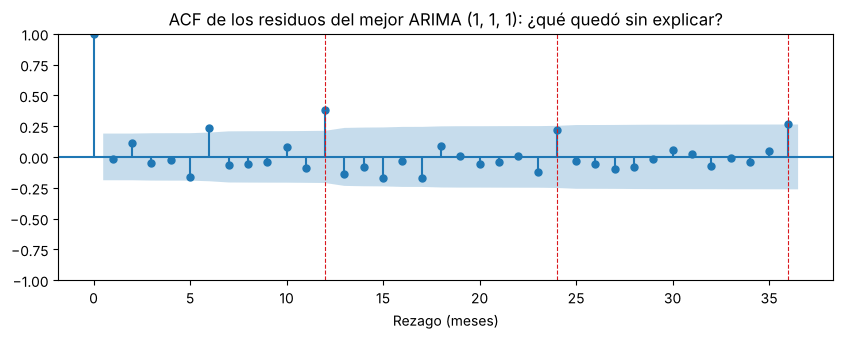

In [15]:
res_mejor_arima = ajustar(y.loc[:FIN_ESTIMACION], ORDEN_MEJOR_ARIMA)

fig, ax = plt.subplots(figsize=(10, 3.2))
plot_acf(res_mejor_arima.resid.iloc[13:], lags=36, ax=ax)   # residuos sin el arranque
for rezago in [12, 24, 36]:
    ax.axvline(rezago, color='#DA181E', linestyle='--', linewidth=0.8)
ax.set_title(f'ACF de los residuos del mejor ARIMA {ORDEN_MEJOR_ARIMA}: ¿qué quedó sin explicar?')
ax.set_xlabel('Rezago (meses)')
plt.show()

**Qué buscamos:** bastones que salen de la banda azul **en los rezagos 12, 24 o 36** (líneas rojas). Si aparecen, el modelo no sabe que **enero se parece a enero** y **septiembre a septiembre**: es la estacionalidad que vimos el Día 1 (por ejemplo, el inicio de clases en la Sierra en septiembre o las fiestas de fin de año). Un ARIMA no tiene cómo ver eso. Por eso subimos al siguiente peldaño.

# 3. Peldaño 2: SARIMA, la memoria estacional

## 3.1 La idea: cuatro letras más

Un SARIMA$(p, d, q)(P, D, Q)_s$ agrega una **segunda capa** que hace lo mismo que $p$, $d$ y $q$, pero mirando **$s$ meses atrás** (para datos mensuales, $s = 12$: el mismo mes del año anterior):

| Letra | Igual que... | pero mirando... | Ejemplo |
|---|---|---|---|
| $P$ | $p$ (AR) | el valor de hace 12 meses | la inflación de septiembre 2025 se parece a la de septiembre 2024 |
| $D$ | $d$ (diferencia) | la diferencia **estacional** $y_t - y_{t-12}$ | modelamos cuánto cambió respecto al mismo mes del año pasado |
| $Q$ | $q$ (MA) | la sorpresa de hace 12 meses | el choque del diciembre pasado deja huella en este diciembre |
| $s$ | — | la longitud del ciclo | 12 en datos mensuales, 4 en trimestrales |

En statsmodels se agrega con `seasonal_order=(P, D, Q, s)`. **Todo lo demás es igual.**

## 3.2 La estrategia: una letra a la vez

Partimos del **mejor ARIMA** (su parte $(p, d, q)$ queda fija) y encendemos la capa estacional **de a una letra**, para ver qué aporta cada una:

| Paso | `seasonal_order` | Qué agregamos |
|---|---|---|
| 1 | $(1, 0, 0, 12)$ | solo $P$: el mismo mes del año pasado |
| 2 | $(0, 0, 1, 12)$ | solo $Q$: la sorpresa del mismo mes del año pasado |
| 3 | $(1, 0, 1, 12)$ | $P$ y $Q$ juntos |
| 4 | $(0, 1, 1, 12)$ | diferencia estacional $D = 1$ con $Q$ (el clásico "modelo aerolínea") |

In [16]:
pasos_sarima = {
    'paso 1 · solo P': (1, 0, 0, 12),
    'paso 2 · solo Q': (0, 0, 1, 12),
    'paso 3 · P y Q': (1, 0, 1, 12),
    'paso 4 · D=1 y Q': (0, 1, 1, 12),
}
p, d, q = ORDEN_MEJOR_ARIMA               # la parte no estacional queda fija: la del mejor ARIMA
filas_sarima, NOMBRE_A_PASO = [], {}
for paso, s_order in pasos_sarima.items():
    P, D, Q, s = s_order
    nombre = f'SARIMA({p},{d},{q})({P},{D},{Q})12 · {paso}'
    NOMBRE_A_PASO[nombre] = s_order
    filas_sarima.append(evaluar(nombre, order=ORDEN_MEJOR_ARIMA, seasonal_order=s_order))

resultados_sarima = tabla(filas_sarima)
resultados_sarima

,MAE_val,RMSE_val,AIC,LjungBox_p12,convergio,vs_PM12_%
modelo,,,,,,
"SARIMA(1,1,1)(1,0,1)12 · paso 3 · P y Q",0.2540,0.3463,34.1645,0.2827,True,2.2985
"SARIMA(1,1,1)(1,0,0)12 · paso 1 · solo P",0.2579,0.3598,50.9439,0.6968,True,3.8855
"SARIMA(1,1,1)(0,0,1)12 · paso 2 · solo Q",0.2586,0.3573,55.6106,0.6285,True,4.1666
"SARIMA(1,1,1)(0,1,1)12 · paso 4 · D=1 y Q",0.2632,0.3545,38.3072,0.8037,True,6.0237


**Cómo leer esta tabla, columna por columna:**

- **`LjungBox_p12`**: es la columna que más debería cambiar respecto al ARIMA. Si ahora es **mayor que 0.05**, la capa estacional "limpió" la autocorrelación del rezago 12.
- **`AIC`**: normalmente baja mucho al agregar la capa estacional (el modelo explica mejor el pasado). El paso 4 tiene $D = 1$, así que su AIC no se compara con los otros tres.
- **`MAE_val`**: la pregunta de fondo. ¿Bajó respecto al mejor ARIMA? ¿Y respecto al PM12?

**En nuestro caso:** los cuatro pasos mejoran (o igualan) al mejor ARIMA, y **todos pasan Ljung-Box** (p > 0.05): la capa estacional capturó lo que faltaba. El AIC cae de ≈ 70 a ≈ 34. El mejor es el **paso 3, $P$ y $Q$ juntos** (MAE ≈ 0.254), a solo ≈ 2 % del PM12. Fíjate que el modelo con mejor Ljung-Box (paso 4) no es el de mejor MAE.

In [17]:
mejor_sarima_nombre = resultados_sarima[resultados_sarima['convergio']].index[0]
ORDEN_ESTACIONAL_MEJOR = NOMBRE_A_PASO[mejor_sarima_nombre]
print('Mejor SARIMA:', mejor_sarima_nombre)
print('seasonal_order:', ORDEN_ESTACIONAL_MEJOR)

Mejor SARIMA: SARIMA(1,1,1)(1,0,1)12 · paso 3 · P y Q
seasonal_order: (1, 0, 1, 12)


## 3.3 Diagnóstico de residuos del mejor SARIMA

`plot_diagnostics` dibuja cuatro gráficos para revisar si los residuos se comportan como **ruido blanco** (lo que el modelo no puede ni debe explicar):

| Gráfico | Qué deberíamos ver |
|---|---|
| Residuos estandarizados (arriba izquierda) | oscilan alrededor de 0, sin patrones ni tramos |
| Histograma (arriba derecha) | forma de campana, parecida a la curva normal |
| Q-Q normal (abajo izquierda) | puntos sobre la recta; las colas que se separan son meses atípicos |
| Correlograma (abajo derecha) | ningún bastón fuera de la banda |

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.5910      0.066      8.898      0.000       0.461       0.721
ma.L1         -0.9956      0.064    -15.674      0.000      -1.120      -0.871
ar.S.L12       0.9958      0.040     24.662      0.000       0.917       1.075
ma.S.L12      -0.9210      0.367     -2.512      0.012      -1.640      -0.202
sigma2         0.0610      0.023      2.653      0.008       0.016       0.106


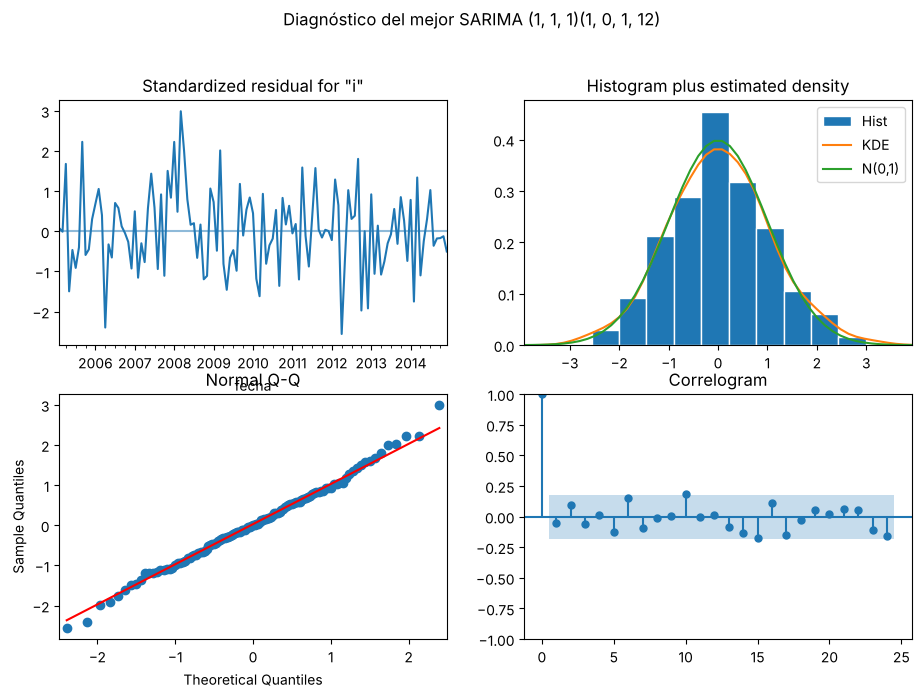

In [18]:
res_mejor_sarima = ajustar(y.loc[:FIN_ESTIMACION], ORDEN_MEJOR_ARIMA, ORDEN_ESTACIONAL_MEJOR)
print(res_mejor_sarima.summary().tables[1])

fig = res_mejor_sarima.plot_diagnostics(figsize=(11, 7), lags=24)
fig.suptitle(f'Diagnóstico del mejor SARIMA {ORDEN_MEJOR_ARIMA}{ORDEN_ESTACIONAL_MEJOR}', y=1.01)
plt.show()

**Cómo leer los coeficientes nuevos:** `ar.S.L12` es $\Phi_1$, el peso del mismo mes del año pasado, y `ma.S.L12` es $\Theta_1$, el peso de la sorpresa de hace 12 meses. Los nombres siguen una lógica: `S` = estacional (*seasonal*), `L12` = rezago (*lag*) 12.

**Dos señales de alerta en nuestros coeficientes** (vale la pena detenerse):

- `ma.L1` ≈ −1. Con $d = 1$, un MA(1) de −1 "deshace" la diferencia: es el síntoma clásico de **sobrediferenciación**. Coincide con la ADF, que decía que la serie ya era estacionaria. El modelo funciona, pero nos avisa que $d = 1$ no era necesario en teoría.
- `ar.S.L12` ≈ 1. El modelo dice que cada mes se parece **casi por completo** al mismo mes del año anterior (suavizado por `ma.S.L12`). Pronostica bien si la estacionalidad es estable, pero **copiará** cualquier choque atípico de un año al siguiente. Lo comprobaremos en el Test (parte 5).

Un buen analista no solo mira el MAE: revisa que los coeficientes tengan sentido.

**Lo que suele aparecer en el Q-Q:** puntos que se alejan en los extremos. Son meses atípicos (la crisis de 2008, la pandemia, el IVA de 2024). Un ARIMA o SARIMA asume choques "normales"; los eventos extremos son, por definición, sorpresas.

# 4. Peldaño 3: SARIMAX, información de afuera

## 4.1 ¿Qué cambia respecto al SARIMA?

Un SARIMA solo mira **el pasado de la propia inflación**. Pero un economista sabe que la inflación también responde a otras cosas: la cantidad de dinero en la economía, el precio del petróleo, el costo de lo que importamos. La **X** de SARIMAX significa **variables exógenas**: series externas que entran como regresores.

$$
\underbrace{y_t}_{\text{inflación}} = \underbrace{\beta_1 x_{1,t} + \beta_2 x_{2,t}}_{\text{parte de regresión (X)}} + \underbrace{\eta_t}_{\text{error con estructura SARIMA}}
$$

Es una **regresión** (como la del Día 1 entre crudo y exportaciones) cuyos errores, en vez de ser ruido, siguen un SARIMA. La parte X explica lo que viene "de afuera"; la parte SARIMA, la memoria que queda.

| | SARIMA | SARIMAX |
|---|---|---|
| Información que usa | solo el pasado de $y$ | pasado de $y$ **y** otras series |
| Coeficientes nuevos | — | un $\beta$ por cada variable X |
| Para pronosticar necesita | nada más | **valores futuros de X** (o supuestos sobre ellos) |
| Clase en statsmodels | `ARIMA(..., seasonal_order=...)` | `SARIMAX(..., exog=X)` |

## 4.2 La regla de oro: X rezagada

Si queremos pronosticar la inflación de **septiembre**, no podemos usar la liquidez de septiembre: **todavía no se publica**. Por eso cada X entra **rezagada un mes** (`shift(1)`): el pronóstico de septiembre usa la información de agosto. Es la misma lógica del `shift(1)` del PM12.

## 4.3 Elegimos las variables con argumento económico

No probamos todas las columnas del archivo: elegimos las que tienen un **canal económico** hacia la inflación de una economía dolarizada.

| Variable X | Cómo se construye | Canal económico |
|---|---|---|
| `m2_anual_l1` | variación anual de la liquidez total (M2), rezagada 1 mes | más dinero en la economía -> más demanda -> presión sobre precios |
| `crudo_anual_l1` | variación anual del precio del crudo Oriente, rezagada 1 mes | petróleo caro -> más ingresos y gasto en la economía; costos de transporte |
| `import_anual_l1` | variación anual de las importaciones FOB, rezagada 1 mes | importamos bienes de consumo e insumos: su costo pasa a precios |

**¿Por qué variaciones anuales y no niveles?** Los niveles (millones de USD, dólares por barril) crecen con el tiempo y no son estacionarios; la inflación sí lo es. Una regresión entre series no estacionarias y una estacionaria daría relaciones espurias (Día 2). La variación anual (`pct_change(12)`) además elimina la estacionalidad propia de cada variable.

In [19]:
# pct_change(12) = variación % respecto al mismo mes del año anterior.  shift(1) = rezago de un mes.
X_todas = pd.DataFrame({
    'm2_anual_l1':     series['liquidez_m2_musd'].pct_change(12).mul(100).shift(1),
    'crudo_anual_l1':  series['precio_crudo_oriente_usd'].pct_change(12).mul(100).shift(1),
    'import_anual_l1': series['importaciones_fob_musd'].pct_change(12).mul(100).shift(1),
}).loc[y.index]          # alineamos con las fechas de la inflación

print('Faltantes por columna:', X_todas.isna().sum().to_dict())
print('\nCorrelación con la inflación del mes (2005–2014, periodo de estimación):')
print(X_todas.loc[:FIN_ESTIMACION].corrwith(y.loc[:FIN_ESTIMACION]).round(3).to_string())

Faltantes por columna: {'m2_anual_l1': 0, 'crudo_anual_l1': 0, 'import_anual_l1': 0}

Correlación con la inflación del mes (2005–2014, periodo de estimación):
m2_anual_l1        0.150
crudo_anual_l1     0.282
import_anual_l1    0.090


**Lectura:** las tres correlaciones son positivas pero **débiles** (≈ 0.09 a 0.28); la más alta es la del crudo. Es solo una pista: la prueba real es si mejoran el **pronóstico** en validación. Que no haya faltantes es importante: `SARIMAX` no acepta huecos en X.

## 4.4 La clase `SARIMAX` y su relación con `ARIMA`

Para que quede claro que **no cambiamos de modelo, solo agregamos información**, comprobamos primero que `SARIMAX` sin X da los **mismos parámetros** que el mejor SARIMA estimado con `ARIMA`:

In [20]:
def ajustar_sarimax(serie, order, seasonal_order=(0, 0, 0, 0), exog=None):
    """Igual que ajustar(), pero con la clase SARIMAX, la 'madre' de ARIMA en statsmodels."""
    d, D = order[1], seasonal_order[1]
    tendencia = 'c' if d + D == 0 else 'n'
    modelo = SARIMAX(serie, exog=exog, order=order, seasonal_order=seasonal_order, trend=tendencia)
    return modelo.fit(disp=False, maxiter=500)     # disp=False: no imprimir cada iteración


sin_x = ajustar_sarimax(y.loc[:FIN_ESTIMACION], ORDEN_MEJOR_ARIMA, ORDEN_ESTACIONAL_MEJOR)
pd.DataFrame({'ARIMA (parte 3)': res_mejor_sarima.params, 'SARIMAX sin X': sin_x.params}).round(4)

,ARIMA (parte 3),SARIMAX sin X
ar.L1,0.5910,0.5910
ma.L1,-0.9956,-0.9956
ar.S.L12,0.9958,0.9958
ma.S.L12,-0.9210,-0.9210
sigma2,0.0610,0.0610


**Idénticos** hasta el cuarto decimal: `ARIMA` y `SARIMAX` estiman exactamente el mismo modelo. Así, cualquier mejora que veamos ahora se deberá a las variables X, no a un cambio de herramienta.

## 4.5 Probar las variables X, una por una y combinadas

Mantenemos fija la parte SARIMA del ganador y solo cambiamos qué X entra.

In [21]:
combinaciones_x = [
    ['m2_anual_l1'],
    ['crudo_anual_l1'],
    ['import_anual_l1'],
    ['m2_anual_l1', 'crudo_anual_l1'],
    ['m2_anual_l1', 'crudo_anual_l1', 'import_anual_l1'],
]
filas_sarimax, COLUMNAS_SARIMAX = [], {}
for columnas in combinaciones_x:
    nombre = 'SARIMAX + ' + ' + '.join(columnas)
    COLUMNAS_SARIMAX[nombre] = columnas
    filas_sarimax.append(evaluar(nombre, ORDEN_MEJOR_ARIMA, ORDEN_ESTACIONAL_MEJOR,
                                 exog=X_todas[columnas], ajustador=ajustar_sarimax))

resultados_sarimax = tabla(filas_sarimax)
resultados_sarimax

,MAE_val,RMSE_val,AIC,LjungBox_p12,convergio,vs_PM12_%
modelo,,,,,,
SARIMAX + m2_anual_l1 + crudo_anual_l1 + import_anual_l1,0.2495,0.3410,35.0560,0.1548,True,0.4815
SARIMAX + m2_anual_l1 + crudo_anual_l1,0.2497,0.3405,33.7775,0.1621,True,0.5759
SARIMAX + m2_anual_l1,0.2526,0.3456,34.2595,0.3243,True,1.7523
SARIMAX + crudo_anual_l1,0.2543,0.3448,32.3093,0.1280,True,2.4322
SARIMAX + import_anual_l1,0.2553,0.3478,35.9403,0.2804,True,2.8245


In [22]:
mejor_sarimax_nombre = resultados_sarimax[resultados_sarimax['convergio']].index[0]
COLUMNAS_X_MEJOR = COLUMNAS_SARIMAX[mejor_sarimax_nombre]
print('Mejor SARIMAX:', mejor_sarimax_nombre)

# ¿Cuánto pesa cada X? Estimamos el ganador con 2005–2014 y miramos sus coeficientes beta.
res_mejor_sarimax = ajustar_sarimax(y.loc[:FIN_ESTIMACION], ORDEN_MEJOR_ARIMA, ORDEN_ESTACIONAL_MEJOR,
                                    X_todas.loc[:FIN_ESTIMACION, COLUMNAS_X_MEJOR])
print(res_mejor_sarimax.summary().tables[1])

Mejor SARIMAX: SARIMAX + m2_anual_l1 + crudo_anual_l1 + import_anual_l1


                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
m2_anual_l1         0.0111      0.011      0.992      0.321      -0.011       0.033
crudo_anual_l1      0.0017      0.001      1.859      0.063   -9.32e-05       0.004
import_anual_l1    -0.0012      0.002     -0.622      0.534      -0.005       0.002
ar.L1               0.5463      0.075      7.324      0.000       0.400       0.693
ma.L1              -0.9969      0.143     -6.970      0.000      -1.277      -0.717
ar.S.L12            0.9962      0.036     28.046      0.000       0.927       1.066
ma.S.L12           -0.9246      0.341     -2.713      0.007      -1.593      -0.257
sigma2              0.0582      0.024      2.379      0.017       0.010       0.106


**Resultado:** **todas** las X mejoran al mejor SARIMA (≈ 0.254), y la combinación de las tres da el menor MAE (≈ 0.2495), prácticamente empatada con liquidez + crudo (≈ 0.2497).

**Cómo leer los $\beta$:**

- `m2_anual_l1` ≈ 0.011: 10 puntos más de crecimiento anual de la liquidez el mes anterior se asocian con ≈ 0.11 puntos más de inflación mensual. Es del orden del error típico de los modelos: no es poco.
- `crudo_anual_l1` ≈ 0.0017: un crudo 30 % más caro que hace un año se asocia con ≈ 0.05 puntos más de inflación.
- `import_anual_l1` tiene signo **negativo** y p-valor alto: no aporta una relación clara.
- **Ninguno es significativo al 5 %** (el crudo está cerca, p ≈ 0.06). La mejora de pronóstico es real pero pequeña, y la evidencia individual de cada variable es débil.

**Parsimonia:** cuando dos modelos casi empatan, un analista prudente prefiere el más simple (aquí, liquidez + crudo, sin la variable de signo dudoso). Mantenemos la regla automática para ser consistentes, pero en un informe esta discusión debe aparecer.

**Advertencia de interpretación:** esto es **asociación predictiva**, no causalidad. Que la liquidez ayude a pronosticar no prueba que cause la inflación; ambas pueden responder a un tercer factor (por ejemplo, el ciclo petrolero).

## 4.6 Un caso especial de X: la variable de intervención (IVA de abril 2024)

El Día 1 vimos que abril de 2024 tuvo un residuo grande por el aumento del IVA del 12 % al 15 %. Una **variable de intervención** (*dummy*) vale 1 en el mes del evento y 0 en el resto, y entra al SARIMAX como una X más.

**¿Por qué no la incluimos en la validación?** Porque la estimación de la validación usa 2005–2014, y en ese periodo la dummy vale **siempre 0**: el modelo no puede estimar su efecto (no hay variación). Solo tiene sentido en una estimación que incluya 2024. Lo ilustramos con la historia hasta diciembre de 2024:

In [23]:
iva_2024 = pd.Series(0.0, index=y.index, name='iva_abril_2024')
iva_2024.loc['2024-04-01'] = 1.0                       # 1 solo en abril de 2024

X_con_iva = X_todas[COLUMNAS_X_MEJOR].join(iva_2024)   # las X del ganador + la dummy

sin_iva = ajustar_sarimax(y_hasta_val, ORDEN_MEJOR_ARIMA, ORDEN_ESTACIONAL_MEJOR, X_todas.loc[:FIN_VAL, COLUMNAS_X_MEJOR])
con_iva = ajustar_sarimax(y_hasta_val, ORDEN_MEJOR_ARIMA, ORDEN_ESTACIONAL_MEJOR, X_con_iva.loc[:FIN_VAL])

print(f"Efecto estimado del IVA: {con_iva.params['iva_abril_2024']:.3f} puntos  (p-valor {con_iva.pvalues['iva_abril_2024']:.3f})")
print(f'AIC sin dummy: {sin_iva.aic:.1f}   ·   AIC con dummy: {con_iva.aic:.1f}')

Efecto estimado del IVA: 0.979 puntos  (p-valor 0.300)
AIC sin dummy: 120.1   ·   AIC con dummy: 109.3


**Lectura:** el modelo atribuye al IVA ≈ 1 punto de inflación **adicional** en abril de 2024, por encima de lo que anticipaban la memoria de la serie y las X; es coherente con un aumento de 3 puntos en el impuesto. Su p-valor es alto (≈ 0.30): con **un solo mes** de evento, el efecto se estima con mucha imprecisión. Aun así el AIC baja ≈ 11 puntos: marcar el evento mejora el ajuste del periodo.

**Para la comparación de la parte 5 no la usamos**: la elección de modelos se hizo en la validación y la respetamos. Una intervención se justifica con un **hecho económico documentado**, nunca con "este mes tuvo un residuo grande".

# 5. La gran comparación: ARIMA vs SARIMA vs SARIMAX vs PM12

## 5.1 En validación (2015–2024)

Reunimos a los tres ganadores y a la línea base. Todos se evaluaron con la misma regla: parámetros de 2005–2014, pronóstico a un paso en 2015–2024.

In [24]:
todas = pd.concat([resultados_arima, resultados_sarima, resultados_sarimax])
finalistas = [mejor_arima_nombre, mejor_sarima_nombre, mejor_sarimax_nombre]
etiquetas = {mejor_arima_nombre: 'Mejor ARIMA', mejor_sarima_nombre: 'Mejor SARIMA', mejor_sarimax_nombre: 'Mejor SARIMAX'}

comparacion_val = todas.loc[finalistas, ['MAE_val', 'RMSE_val', 'LjungBox_p12', 'vs_PM12_%']].rename(index=etiquetas)
comparacion_val.loc['Línea base PM12'] = [MAE_PM12, np.sqrt((errores_pm12_val ** 2).mean()), np.nan, 0.0]
for nombre, etiqueta in etiquetas.items():
    print(f'{etiqueta:14s} = {nombre}')
comparacion_val.sort_values('MAE_val').round(4)

Mejor ARIMA    = ARIMA(1,1,1)
Mejor SARIMA   = SARIMA(1,1,1)(1,0,1)12 · paso 3 · P y Q
Mejor SARIMAX  = SARIMAX + m2_anual_l1 + crudo_anual_l1 + import_anual_l1


,MAE_val,RMSE_val,LjungBox_p12,vs_PM12_%
modelo,,,,
Línea base PM12,0.2483,0.3397,NaN,0.0000
Mejor SARIMAX,0.2495,0.3410,0.1548,0.4815
Mejor SARIMA,0.2540,0.3463,0.2827,2.2985
Mejor ARIMA,0.2631,0.3581,0.0012,5.9811


## 5.2 En el Test (ene 2025 – ago 2026): una sola vez

Ahora los modelos están **decididos**. Para el Test, el "train" es **toda la historia hasta diciembre de 2024** (2005–2024): es la información que un analista habría tenido el 1 de enero de 2025. Repetimos los tres pasos: estimar con 2005–2024, aplicar a toda la serie, predecir a un paso cada mes de 2025–2026.

In [25]:
def pronostico_test(order, seasonal_order, columnas_x=None):
    """Estima con 2005–2024 y pronostica a un paso ene 2025 – ago 2026."""
    X = None if columnas_x is None else X_todas[columnas_x]
    ajustador = ajustar if columnas_x is None else ajustar_sarimax
    res = ajustador(y_hasta_val, order, seasonal_order, None if X is None else X.loc[:FIN_VAL])   # train = 2005–2024
    return res.apply(y, exog=X).predict(start=INICIO_TEST, end=FIN_TEST)                          # Test a un paso


pred_test = pd.DataFrame({
    'Mejor ARIMA': pronostico_test(ORDEN_MEJOR_ARIMA, (0, 0, 0, 0)),
    'Mejor SARIMA': pronostico_test(ORDEN_MEJOR_ARIMA, ORDEN_ESTACIONAL_MEJOR),
    'Mejor SARIMAX': pronostico_test(ORDEN_MEJOR_ARIMA, ORDEN_ESTACIONAL_MEJOR, COLUMNAS_X_MEJOR),
    'Línea base PM12': pm12.loc[INICIO_TEST:FIN_TEST],
})
errores_test = pred_test.rsub(y_test, axis=0)          # real − pronóstico, para cada modelo

comparacion_test = pd.DataFrame({
    'MAE_Test': errores_test.abs().mean(),
    'RMSE_Test': np.sqrt((errores_test ** 2).mean()),
    'Sesgo_Test': -errores_test.mean(),                  # positivo = el modelo sobreestima la inflación
})
comparacion_test['vs_PM12_%'] = 100 * (comparacion_test['MAE_Test'] / comparacion_test.loc['Línea base PM12', 'MAE_Test'] - 1)
comparacion_test.sort_values('MAE_Test').round(4)

,MAE_Test,RMSE_Test,Sesgo_Test,vs_PM12_%
Línea base PM12,0.2857,0.4049,-0.0665,0.0000
Mejor ARIMA,0.3075,0.4291,-0.0504,7.6616
Mejor SARIMAX,0.3188,0.4593,-0.0375,11.5870
Mejor SARIMA,0.3230,0.4643,-0.0461,13.0767


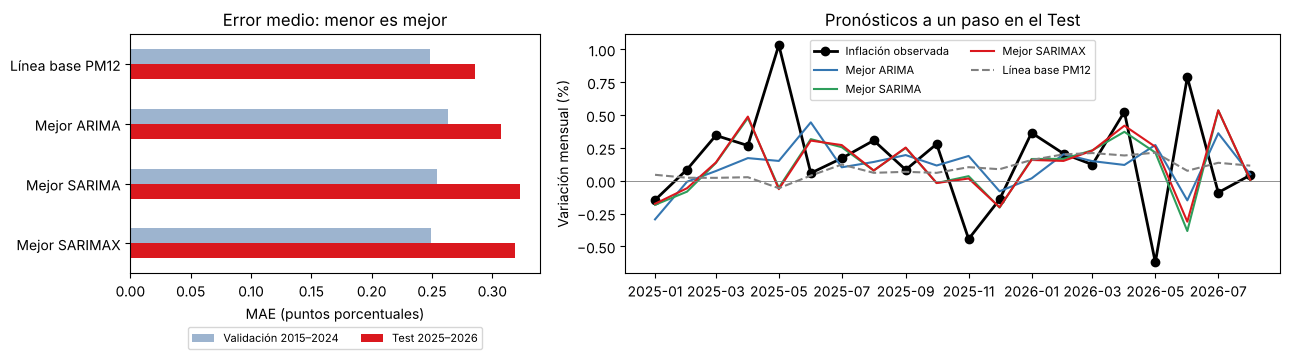

In [26]:
colores = {'Mejor ARIMA': '#3476B1', 'Mejor SARIMA': '#2E9E5B', 'Mejor SARIMAX': '#DA181E', 'Línea base PM12': 'gray'}
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={'width_ratios': [1, 1.6]})

# Izquierda: MAE en validación y en Test, lado a lado
orden_barras = ['Línea base PM12', 'Mejor ARIMA', 'Mejor SARIMA', 'Mejor SARIMAX']
mae = pd.DataFrame({'Validación 2015–2024': comparacion_val['MAE_val'],
                    'Test 2025–2026': comparacion_test['MAE_Test']}).loc[orden_barras]
mae.plot.barh(ax=axes[0], color=['#9DB4CF', '#DA181E'])
axes[0].invert_yaxis()
axes[0].set_xlabel('MAE (puntos porcentuales)')
axes[0].set_title('Error medio: menor es mejor')
axes[0].legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2, fontsize=8)

# Derecha: pronósticos a un paso en el Test
axes[1].plot(y_test, color='black', marker='o', linewidth=2, label='Inflación observada')
for nombre, serie_pred in pred_test.items():
    axes[1].plot(serie_pred, color=colores[nombre], linestyle='--' if 'PM12' in nombre else '-', label=nombre)
axes[1].axhline(0, color='gray', linewidth=0.6)
axes[1].set_ylabel('Variación mensual (%)')
axes[1].set_title('Pronósticos a un paso en el Test')
axes[1].legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

## 5.3 Lectura: ¿valió la pena subir la escalera?

| Puesto | Validación 2015–2024 (MAE) | Test 2025–2026 (MAE) |
|---|---|---|
| 1.º | PM12 (≈ 0.248) | PM12 (≈ 0.286) |
| 2.º | SARIMAX (≈ 0.250) | ARIMA (≈ 0.308) |
| 3.º | SARIMA (≈ 0.254) | SARIMAX (≈ 0.319) |
| 4.º | ARIMA (≈ 0.263) | SARIMA (≈ 0.323) |

1. **Validación:** cada peldaño mejoró al anterior: ARIMA → SARIMA → SARIMAX. El SARIMAX quedó a solo ≈ 0.5 % del PM12: prácticamente un **empate**, pero el PM12 sigue primero.
2. **Test:** el orden **se invierte**: los modelos con capa estacional quedan últimos. 2024 fue un año atípico (subida del IVA en abril, crisis eléctrica en el último trimestre) y el término estacional, con $\Phi_1 \approx 1$, **copia** esos choques en los mismos meses de 2025: el mismo problema del ingenuo estacional del Día 1. Las X ayudan un poco al SARIMA, pero no lo rescatan.
3. **Sesgo:** todos son negativos (≈ −0.04 a −0.07): todos **subestiman** ligeramente la inflación de 2025–2026.

**La lección del día:** que un modelo tenga mejor AIC o residuos más limpios **no garantiza** que pronostique mejor. El PM12 es muy difícil de vencer en la inflación mensual del Ecuador porque la serie tiene mucho ruido y poca memoria aprovechable. Reconocer que un modelo complejo no mejora a uno simple **es un resultado válido**, no un fracaso.

**¿Entonces para qué sirven ARIMA, SARIMA y SARIMAX?** Por lo que el PM12 no ofrece:

| Aporte | PM12 | ARIMA / SARIMA | SARIMAX |
|---|:---:|:---:|:---:|
| Intervalos de predicción con fundamento estadístico | — | ✓ | ✓ |
| Interpretación de la dinámica (persistencia, estacionalidad) | — | ✓ | ✓ |
| Diagnóstico de lo que quedó sin explicar | — | ✓ | ✓ |
| Escenarios ("¿y si la liquidez crece 5 puntos más?") | — | — | ✓ |

## 5.4 Pronóstico de septiembre a noviembre de 2026

Para el pronóstico final, cada modelo se reestima con **toda** la historia (hasta agosto de 2026).

**El reto del SARIMAX:** para pronosticar octubre y noviembre necesita la X de septiembre y octubre, que **aún no conocemos**. Septiembre sí se puede (usa la X de agosto, por el rezago de un mes). Para los otros dos meses debemos **suponer** algo. Aquí usamos el supuesto más simple y transparente: **la X se mantiene en su último valor observado**. En el Día 6 cambiaremos este supuesto para construir escenarios.

In [27]:
H = 3                                                             # horizonte: sep, oct y nov de 2026
fechas_futuras = pd.date_range(y.index[-1] + pd.offsets.MonthBegin(), periods=H, freq='MS')

# --- X futura del SARIMAX ---
# Septiembre usa la X de agosto (ya observada). Calculamos las variaciones SIN el shift y tomamos agosto.
x_ultimo = pd.DataFrame({
    'm2_anual_l1':     series['liquidez_m2_musd'].pct_change(12).mul(100),
    'crudo_anual_l1':  series['precio_crudo_oriente_usd'].pct_change(12).mul(100),
    'import_anual_l1': series['importaciones_fob_musd'].pct_change(12).mul(100),
}).loc[y.index[-1], COLUMNAS_X_MEJOR]
# Supuesto: octubre y noviembre repiten ese mismo valor (la X "se queda quieta").
X_futuro = pd.DataFrame([x_ultimo.values] * H, index=fechas_futuras, columns=COLUMNAS_X_MEJOR)
print('X que usará el SARIMAX (supuesto: se mantiene el último valor observado):')
display(X_futuro.round(2))

# --- Reestimamos cada finalista con TODA la historia (train = 2005 – ago 2026) y pronosticamos ---
finales = {
    'Mejor ARIMA': ajustar(y, ORDEN_MEJOR_ARIMA).get_forecast(H),
    'Mejor SARIMA': ajustar(y, ORDEN_MEJOR_ARIMA, ORDEN_ESTACIONAL_MEJOR).get_forecast(H),
    'Mejor SARIMAX': ajustar_sarimax(y, ORDEN_MEJOR_ARIMA, ORDEN_ESTACIONAL_MEJOR,
                                     X_todas[COLUMNAS_X_MEJOR]).get_forecast(H, exog=X_futuro),
}
tabla_pronostico = pd.DataFrame({nombre: f.predicted_mean for nombre, f in finales.items()})
tabla_pronostico['Línea base PM12'] = y.iloc[-12:].mean()        # el PM12 pronostica lo mismo en todo el horizonte
tabla_pronostico.index = tabla_pronostico.index.strftime('%b %Y')
tabla_pronostico.round(3)

X que usará el SARIMAX (supuesto: se mantiene el último valor observado):


,m2_anual_l1,crudo_anual_l1,import_anual_l1
2026-09-01,9.1,31.5,32.27
2026-10-01,9.1,31.5,32.27
2026-11-01,9.1,31.5,32.27


,Mejor ARIMA,Mejor SARIMA,Mejor SARIMAX,Línea base PM12
Sep 2026,0.098,0.157,0.157,0.094
Oct 2026,0.114,0.041,0.059,0.094
Nov 2026,0.118,-0.093,-0.080,0.094


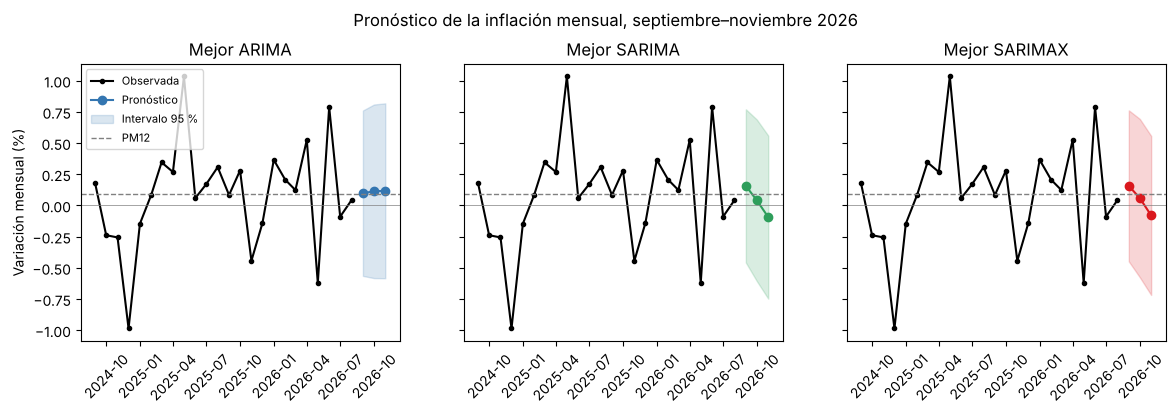

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
for ax, (nombre, f) in zip(axes, finales.items()):
    intervalo = f.conf_int(alpha=0.05)                        # 95 %: alpha = 1 − nivel
    ax.plot(y.loc['2024-09':], color='black', marker='o', markersize=3, label='Observada')
    ax.plot(f.predicted_mean, color=colores[nombre], marker='o', label='Pronóstico')
    ax.fill_between(intervalo.index, intervalo.iloc[:, 0], intervalo.iloc[:, 1],
                    color=colores[nombre], alpha=0.18, label='Intervalo 95 %')
    ax.axhline(y.iloc[-12:].mean(), color='gray', linestyle='--', linewidth=1, label='PM12')
    ax.axhline(0, color='gray', linewidth=0.5)
    ax.set_title(nombre)
    ax.tick_params(axis='x', rotation=45)
axes[0].set_ylabel('Variación mensual (%)')
axes[0].legend(fontsize=8)
plt.suptitle('Pronóstico de la inflación mensual, septiembre–noviembre 2026', y=1.03)
plt.show()

**Lectura:**

- Para **septiembre**, los tres modelos dan entre ≈ 0.10 % y 0.16 %, cerca del PM12 (≈ 0.09 %).
- Para **octubre y noviembre**, SARIMA y SARIMAX bajan (hasta ≈ −0.09 % en noviembre) porque **repiten el patrón estacional** de esos meses (noviembre fue negativo en 2024 y en 2025). El ARIMA, sin capa estacional, se queda cerca de 0.11 %.
- Los intervalos del 95 % van de ≈ −0.6 % a ≈ +0.8 %: más de **un punto porcentual** de ancho, mucho más que la diferencia entre modelos. **Esto no es un defecto, es información:** la inflación mensual del Ecuador es difícil de anticipar mes a mes, y comunicarlo es parte del trabajo del analista.

> **Intervalo de predicción ≠ intervalo de confianza.** El de confianza (Día 2) se refiere a un **parámetro** (por ejemplo $\phi$). El de predicción se refiere a un **valor futuro** de la serie, e incluye el choque que nadie puede anticipar. Por eso es mucho más ancho.

# 6. VAR y cointegración (2.5, conceptual)

El SARIMAX usa variables externas, pero en **una sola dirección**: la liquidez ayuda a pronosticar la inflación, y no al revés. En economía las variables se influyen **mutuamente**. Dos ideas permiten modelar eso; hoy las vemos de forma conceptual.

## 6.1 Modelo VAR (vector autorregresivo)

Un **VAR** es un AR con **varias series a la vez**: cada variable depende de sus propios rezagos **y** de los rezagos de las otras. Con dos variables, inflación ($\pi$) y precio del petróleo ($p$):

$$
\begin{aligned}
\pi_t &= c_1 + a_{11}\,\pi_{t-1} + a_{12}\,p_{t-1} + \varepsilon_{1t} \\
p_t &= c_2 + a_{21}\,\pi_{t-1} + a_{22}\,p_{t-1} + \varepsilon_{2t}
\end{aligned}
$$

| | SARIMAX | VAR |
|---|---|---|
| Variables que se pronostican | una ($y$) | todas a la vez |
| Dirección de la influencia | X -> y | en todas las direcciones |
| ¿Necesita supuestos sobre X futura? | sí | no: las pronostica él mismo |
| Costo | pocos parámetros | crece rápido: 5 variables y 2 rezagos = 55 coeficientes |

Es una herramienta habitual en bancos centrales para estudiar cómo un choque se transmite (**funciones impulso-respuesta**). En statsmodels: `from statsmodels.tsa.api import VAR`.

## 6.2 Cointegración

A veces **dos series no estacionarias se mueven juntas** en el largo plazo: cada una sube y baja, pero la distancia entre ellas es estable. Se dice que están **cointegradas**.

**Ejemplo intuitivo:** una persona y su perro con correa. Cada uno camina sin rumbo fijo (no estacionarios), pero la distancia entre ellos nunca supera el largo de la correa (estacionaria).

**Cómo se prueba:** con la prueba de **Engle-Granger** (`coint` en statsmodels). $H_0$: **no** hay cointegración.

### Ilustración con exportaciones e importaciones

ADF exportaciones (p): 0.743
ADF importaciones (p): 0.734
ADF balanza (p):       0.238
Engle-Granger exportaciones–importaciones (p): 0.293


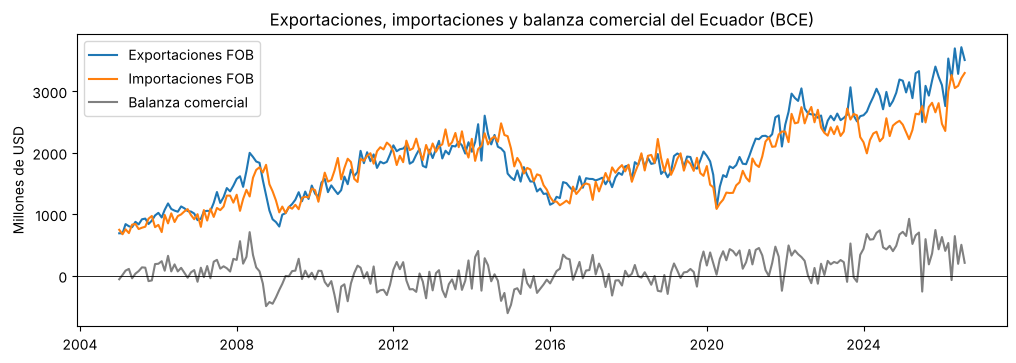

In [29]:
exportaciones = series['exportaciones_fob_musd'].loc['2005':'2026-08']
importaciones = series['importaciones_fob_musd'].loc['2005':'2026-08']
balanza = series['balanza_comercial_musd'].loc['2005':'2026-08']

print('ADF exportaciones (p):', round(adfuller(exportaciones)[1], 3))
print('ADF importaciones (p):', round(adfuller(importaciones)[1], 3))
print('ADF balanza (p):      ', round(adfuller(balanza)[1], 3))
print('Engle-Granger exportaciones–importaciones (p):', round(coint(exportaciones, importaciones)[1], 3))

fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(exportaciones, label='Exportaciones FOB')
ax.plot(importaciones, label='Importaciones FOB')
ax.plot(balanza, label='Balanza comercial', color='gray')
ax.axhline(0, color='black', linewidth=0.6)
ax.set_ylabel('Millones de USD')
ax.set_title('Exportaciones, importaciones y balanza comercial del Ecuador (BCE)')
ax.legend()
plt.show()

### Lectura

- Exportaciones e importaciones **no son estacionarias** (p alto en la ADF): crecen con el tiempo.
- La prueba de Engle-Granger **no rechaza** $H_0$ (p > 0.05): no hay evidencia de una relación de largo plazo estable en todo el periodo.
- El gráfico muestra por qué: la brecha entre ambas series cambió de forma persistente (déficits en 2009 y 2015, superávits más frecuentes desde 2020).

**Conclusión conceptual:** que dos series se parezcan en un gráfico no basta para afirmar una relación de largo plazo; hay que **probarla**.

# 7. Una serie como problema de aprendizaje supervisado (3.1)

## 7.1 La idea

En el Módulo 3, un modelo supervisado necesitaba una tabla con **columnas X** (predictores) y **una columna y** (objetivo). ¿Cómo usar Random Forest con una serie? **Construyendo la tabla con rezagos:** cada fila es un mes; el objetivo es la inflación de ese mes y los predictores son valores **anteriores**. Es lo mismo que hicimos con las X del SARIMAX, pero ahora con la propia serie.

In [30]:
tabla_rezagos = pd.DataFrame({
    'rezago_12': y.shift(12),     # mismo mes del año anterior (lo que usa la parte estacional del SARIMA)
    'rezago_2': y.shift(2),
    'rezago_1': y.shift(1),       # mes anterior (lo que usa un AR(1))
    'objetivo': y,
}).dropna()                       # quitamos las filas incompletas (el primer año)

print('Filas de la tabla:', len(tabla_rezagos), '(se pierden las 12 primeras por el rezago 12)')
tabla_rezagos.loc['2025-01':'2025-03'].round(2)

Filas de la tabla: 248 (se pierden las 12 primeras por el rezago 12)


,rezago_12,rezago_2,rezago_1,objetivo
fecha,,,,
2025-01-01,0.13,-0.26,-0.99,-0.15
2025-02-01,0.09,-0.99,-0.15,0.09
2025-03-01,0.29,-0.15,0.09,0.35


## 7.2 Comprobación: una regresión lineal sobre el rezago 1 es un AR(1)

Si la tabla está bien construida, una `LinearRegression` del Módulo 3 con `rezago_1` como único predictor debe dar casi los mismos coeficientes que el AR(1) del Día 2 (estimado hasta 2023).

In [31]:
tabla_ar = pd.DataFrame({'rezago_1': y.shift(1), 'objetivo': y}).dropna().loc[:'2023-12']
regresion = LinearRegression().fit(tabla_ar[['rezago_1']], tabla_ar['objetivo'])

print('Intercepto (c):    ', round(regresion.intercept_, 4))
print('Coeficiente (phi): ', round(regresion.coef_[0], 4))

Intercepto (c):     0.1173
Coeficiente (phi):  0.477


**Coinciden con el AR(1) del Día 2** ($c \approx 0.117$, $\phi \approx 0.477$). Un AR(1) **es** una regresión lineal sobre una tabla de rezagos. Mañana cambiamos `LinearRegression` por `RandomForestRegressor`, agregamos más columnas (rezagos, mes del año, promedios móviles) y comparamos con los ganadores de hoy.

### Cuidados que heredamos del Día 0

- **Solo rezagos positivos** como predictores (`shift(1)`, `shift(12)`); nunca `shift(-1)`.
- **No mezclar las filas al azar** para dividir Train y Test: el corte sigue siendo por fecha.

# 8. Actividad 2 · Mi primer pronóstico ARIMA (20 puntos)

**Trabajo individual · 40 minutos.** Abre el notebook `Actividad2_ARIMA.ipynb` (en esta misma carpeta, o con su botón de Colab), ejecútalo completo, cambia el parámetro indicado y responde las cuatro preguntas dentro del archivo:

1. ¿Qué se pronosticó?
2. ¿Cómo cambió el resultado al modificar el parámetro?
3. ¿Qué muestran los errores?
4. ¿Qué limitaciones observas?

Puedes usar un agente de IA para entender o corregir el código; las respuestas deben basarse en los resultados de tu notebook.

# 9. Reto de cierre: riesgo país

Repite la escalera del día con `riesgo_pais_pb` desde 2005:

1. ¿Es estacionaria? Usa ADF. ¿Qué $d$ propones?
2. Prueba al menos un modelo de cada tipo de ARIMA (cambia `y` por la nueva serie y vuelve a ejecutar desde la parte 1).
3. ¿Tiene sentido un SARIMA en esta serie? Mira la ACF de los residuos en el rezago 12.
4. Propón una X con argumento económico (pista: el precio del crudo) y prueba un SARIMAX.
5. ¿Alguno supera al pronóstico ingenuo, que el Día 1 ganó en esta serie?

In [32]:
riesgo = series['riesgo_pais_pb'].loc['2005':].dropna()
print(f'{len(riesgo)} meses · último dato: {riesgo.index.max():%b %Y} = {riesgo.iloc[-1]:.0f} puntos básicos')

261 meses · último dato: Sep 2026 = 439 puntos básicos


In [33]:
# A partir de aquí escribe tus propias celdas.

## Checklist del día

- [ ] ¿Sé qué significan $p$, $d$, $q$ y reconozco los 4 tipos de ARIMA por su orden?
- [ ] ¿Sé qué agrega cada letra estacional $(P, D, Q, s)$?
- [ ] ¿Entiendo por qué las X de un SARIMAX entran **rezagadas** y qué supuesto hice sobre su futuro?
- [ ] ¿Estimé cada modelo solo con datos **anteriores** al periodo evaluado?
- [ ] ¿Comparé AIC **solo** entre modelos con el mismo $d$ y $D$?
- [ ] ¿Revisé los residuos (Ljung-Box, `plot_diagnostics`)?
- [ ] ¿Comparé contra el PM12 y acepté el resultado aunque el modelo simple ganara?
- [ ] ¿Presenté el pronóstico **con su intervalo**?

**Puente hacia el Día 4:** ya tenemos una tabla de rezagos. Mañana la ampliaremos y entrenaremos un Random Forest con validación temporal, y lo compararemos con el PM12 y los ganadores de hoy.